# Importing packages and functions

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator
from VoI_Code import *

# Running the Value of Information calculations

In [ ]:


mean = 500
n = 5000
D = np.linspace(mean-200, mean+200, 101)
D_list = D

alphas = np.linspace(1.7,4,20)
SD = np.linspace(0, 140, 20)  # Standard deviations

# Initialize 2D arrays to hold EVPI values for each alpha and SD
EVPI_matrix = np.zeros((len(alphas), len(SD)))
EVPI_profit_matrix = np.zeros((len(alphas), len(SD)))

rerun = 3

for i, alpha in enumerate(alphas):
    for j, sd in enumerate(SD):
        EVPI_sum = 0
        EVPI_profit_sum = 0
        for _ in range(rerun):  # Run the code multiple times for each standard deviation
            random_x = np.random.normal(mean, sd, n)
            x = np.clip(random_x, a_min=0.00000001, a_max=None)  # Ensuring all x are positive
            x_list = x
            
            EVPI = post(x_list, D_list, n, alpha)[0] - prior(x_list, D_list, n, alpha)[0]
            EVPI_sum += EVPI
            
            # Calculate insurer's EVPI
            EVPI_profit = post(x_list, D_list, n, alpha)[1] - prior(x_list, D_list, n, alpha)[1]
            EVPI_profit_sum += EVPI_profit
        
        # Calculate average EVPI for the current standard deviation
        avg_EVPI = EVPI_sum / rerun
        avg_EVPI_profit = EVPI_profit_sum / rerun
        
        # Store the values in the matrices
        EVPI_matrix[i, j] = avg_EVPI
        EVPI_profit_matrix[i, j] = avg_EVPI_profit
    print(i, alpha, 'done')
        
# Create meshgrids for contour plotting
SD_grid, alpha_grid = np.meshgrid(SD, alphas)

# Plotting
plt.figure(figsize=(12, 6))

# Contour plot for client EVPI
plt.subplot(1, 2, 1)
contour1 = plt.contourf(SD_grid, alpha_grid, EVPI_matrix, cmap='viridis', levels =100)
plt.colorbar(contour1)
plt.title('Client EVPI')
plt.xlabel('Prior $\sigma$ in m/s')
plt.ylabel('Alpha')


min_val = EVPI_matrix.min()
max_val = EVPI_matrix.max()


vmax = max_val
vmin = -vmax

# Contour plot for insurer EVPI
plt.subplot(1, 2, 2)
contour2 = plt.contourf(SD_grid, alpha_grid, EVPI_profit_matrix, vmin = vmin, vmax = vmax,  levels=50,cmap='seismic')
plt.colorbar(contour2)
plt.title('Insurer EVPI')
plt.xlabel('Prior $\sigma$ in m/s')
plt.ylabel('Alpha')

plt.tight_layout()
plt.show()





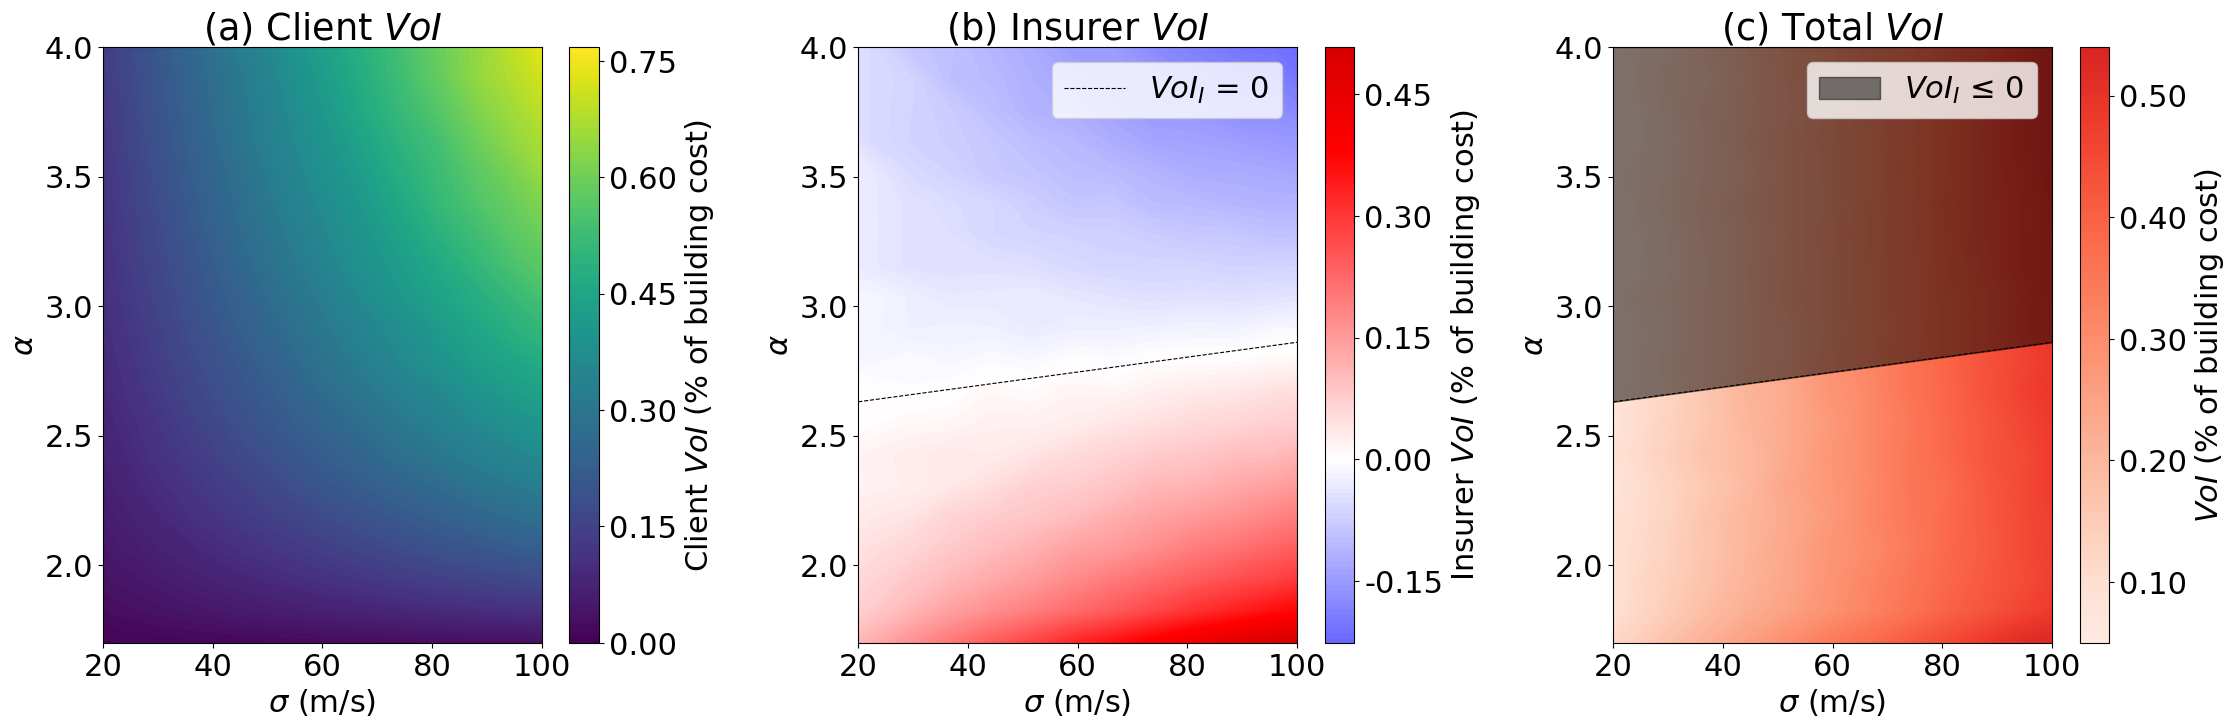

In [26]:
plt.rcParams.update({'font.size': 22})
def zero(x):
    return 2.86 + (x-100)*(23/8000)

a = 110
SD = np.linspace(0, 140, 20)  # Standard deviations
SD_filtered = SD[(SD >= 14) & (SD <= a)]  # Filter SD for the desired range
SD_grid, alpha_grid = np.meshgrid(SD_filtered, alphas)

# Filter matrices for the corresponding SD range
EVPI_matrix_filtered = EVPI_matrix[:, (SD >= 14) & (SD <= a)]
EVPI_profit_matrix_filtered = EVPI_profit_matrix[:, (SD >= 14) & (SD <= a)]

plt.figure(figsize=(23, 8))

# Contour plot for client EVPI
plt.subplot(1, 3, 1)
contour1 = plt.contourf(SD_grid, alpha_grid, EVPI_matrix_filtered, cmap='viridis', levels=100)
cbar = plt.colorbar(contour1, label=f'Client $VoI$ (% of building cost)')
cbar.locator = MaxNLocator(nbins=6)
cbar.update_ticks()
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))

plt.title(f'(a) Client $VoI$')
plt.xlabel('$\sigma$ (m/s)')
plt.ylabel(r'$\alpha$')
plt.xlim(20, 100)

vmax = EVPI_matrix_filtered.max()
vmin = -vmax

plt.tight_layout(pad=3)

# Contour plot for insurer EVPI
x = SD_filtered
line = []
for i in x:
    line.append(zero(i))

y2 = np.ones_like(x) * 4  # Set y2 as a constant line at y = 4

plt.subplot(1, 3, 2)
plt.plot(x, line, linewidth=0.8, linestyle='--', color='k', label=r'$VoI_{I}$ = 0')

contour2 = plt.contourf(SD_grid, alpha_grid, EVPI_profit_matrix_filtered, vmin=vmin, vmax=vmax, levels=790, cmap='seismic')
cbar = plt.colorbar(contour2, label=f'Insurer $VoI$ (% of building cost)')
cbar.locator = MaxNLocator(nbins=6)
cbar.update_ticks()
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))

plt.xlim(20, 100)
plt.title(f'(b) Insurer $VoI$')
plt.xlabel('$\sigma$ (m/s)')
plt.legend()
plt.ylabel(r'$\alpha$')

# Contour plot for total VoI
plt.subplot(1, 3, 3)
plt.plot(x, line, linewidth=0.8, linestyle='--', color='k')

total_VoI_filtered = EVPI_profit_matrix_filtered + EVPI_matrix_filtered
contour3 = plt.contourf(SD_grid, alpha_grid, total_VoI_filtered, vmin=0, vmax=vmax, levels=500, cmap='Reds')
cbar = plt.colorbar(contour3, label=f'$VoI$ (% of building cost)')
cbar.locator = MaxNLocator(nbins=6)
cbar.update_ticks()
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))

plt.title(f'(c) Total $VoI$')
plt.xlabel('$\sigma$ (m/s)')
plt.ylabel(r'$\alpha$')

plt.fill_between(x, line, y2, color='k', alpha=0.5, label=r'$VoI_{I}$ ≤ 0')
plt.legend()
plt.xlim(20, 100)

plt.tight_layout(pad=1.5)

plt.show()
